# Avance 3.8. Modelo baseline con PTB-XL

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

En el Avance 1 exploramos PTB-XL 1.0.3 y en el Avance 2 convertimos cada ECG en 111 características con significado clínico. En este avance construimos el primer modelo: un baseline, es decir, la solución más simple que todavía tiene sentido para el problema. Sirve para tres cosas:

1. Saber si el problema es viable. Si un modelo simple no supera al azar, los datos no traen información suficiente o el problema es muy difícil.
2. Tener una referencia. Cualquier modelo más complejo de los avances siguientes tendrá que superarlo para justificar su costo.
3. Ajustar expectativas con el equipo y con el patrocinador, con números medidos y no supuestos.

El notebook responde, en orden, las cinco preguntas del avance: qué métrica usar, cuál es el desempeño mínimo, qué algoritmo elegir, qué características importan y si el modelo está sub o sobreajustado. Al final verificamos el desempeño en el pliegue de prueba, que no se usó en ninguna decisión.

Igual que en los avances anteriores, la tarea es el tamizaje binario del proyecto. Clase 1, cardiopatía: el ECG tiene algún código de `MI`, `STTC`, `CD` o `HYP`. Clase 0, normal: solo tiene `NORM`. PTB-XL es un sustituto público mientras llegan los datos del patrocinador, así que los números describen a PTB-XL y no a una población universitaria.

## 1. Configuración y datos de entrada

El notebook parte de la tabla que entregó el Avance 2 (`outputs/avance2_fusion/`). Si no existe, la primera celda ejecuta `Avance2.8.ipynb` para generarla (unos 5 minutos), así que este notebook se puede correr por sí solo con los datos crudos de PTB-XL en `data/raw/ptb-xl/1.0.3`.

In [1]:
import os

N_JOBS = min(8, os.cpu_count())
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import json
import platform
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import RFE, RFECV
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate, learning_curve
from sklearn.tree import DecisionTreeClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from ecg_experiment.intervals import metric_intervals, paired_auroc_difference, patient_groups, patient_resample
from ecg_experiment.paths import to_stored

AVANCE2 = Path(os.environ.get("AVANCE2_OUT", ROOT / "outputs/avance2_fusion"))
OUT = Path(os.environ.get("AVANCE3_OUT", ROOT / "outputs/avance3_baseline"))
OUT.mkdir(parents=True, exist_ok=True)
TABLE = AVANCE2 / "ptbxl_caracteristicas_seleccionadas.csv"

if not TABLE.exists():
    import nbformat
    from nbclient import NotebookClient
    print("No está la tabla del Avance 2; se ejecuta Avance2.8.ipynb para generarla (unos 5 minutos).")
    avance2 = nbformat.read(ROOT / "notebooks/Avance2.8.ipynb", as_version=4)
    NotebookClient(avance2, timeout=None, resources={"metadata": {"path": str(ROOT / "notebooks")}}).execute()

SEED = 42
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", rc={"figure.dpi": 110, "axes.titlesize": 11})
VERSIONS = {p: version(p) for p in ("numpy", "pandas", "scikit-learn", "seaborn", "matplotlib")}
print(f"Python {platform.python_version()} | " + " | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

Python 3.11.13 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | seaborn 0.13.2 | matplotlib 3.11.2


In [2]:
data = pd.read_csv(TABLE, index_col="ecg_id")
dictionary = pd.read_csv(AVANCE2 / "variables_finales.csv").set_index("variable")
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
METADATA = ["meta_age_group", "meta_sex"]
FEATURES = list(dictionary.index)
assert set(FEATURES) | set(METADATA) | {"patient_id", "strat_fold", "split", "target", *SUPERCLASSES} == set(data.columns)
assert data[FEATURES].notna().all().all()

FAMILY = dictionary.familia
FAMILIES = list(FAMILY.value_counts().index)
FAMILY_COLORS = dict(zip(FAMILIES, sns.color_palette("colorblind", len(FAMILIES))))

X, y = data[FEATURES], data.target.astype(int)
patients, folds = data.patient_id.to_numpy(), data.strat_fold
train, val, test = (data.split == s for s in ("train", "val", "test"))
CV = PredefinedSplit(folds[train].to_numpy())

partition = data.groupby("split", sort=False).agg(
    pliegues=("strat_fold", lambda f: f"{f.min()}-{f.max()}" if f.nunique() > 1 else str(f.iloc[0])),
    ECG=("target", "size"), pacientes=("patient_id", "nunique"), cardiopatia_pct=("target", lambda t: 100 * t.mean()),
).loc[["train", "val", "test"]]
display(partition.round(1))
shared = set(data.patient_id[train]) & (set(data.patient_id[val]) | set(data.patient_id[test]))
print(f"{len(FEATURES)} características de la señal | pacientes en train y en otra partición: {len(shared)}")
display(FAMILY.value_counts().rename("características").to_frame().T)

,pliegues,ECG,pacientes,cardiopatia_pct
split,,,,
train,1-8,17083,14822,57.6
val,9,2146,1917,57.4
test,10,2158,1877,57.7


111 características de la señal | pacientes en train y en otra partición: 0


familia,QRS: amplitud y eje,Repolarización (ST-T),Estadísticos de la señal,Intervalos,Espectro,Ritmo,Calidad,Onda P
características,47,27,23,6,3,3,1,1


La tabla tiene 21,387 ECG: 17,083 de entrenamiento (14,822 pacientes), 2,146 de validación (1,917) y 2,158 de prueba (1,877). La prevalencia de cardiopatía es casi la misma en las tres particiones (57.6%, 57.4% y 57.7%) y ningún paciente de entrenamiento aparece en validación o en prueba.

Las 111 características se reparten en ocho familias. Las más grandes son las que se miden por derivación: amplitud y eje del QRS (47), repolarización ST-T (27) y estadísticos de la señal (23). La edad y el sexo vienen en un bloque aparte y, como se decidió en el Avance 2, no entran al modelo.

Usamos las particiones que publican los autores de PTB-XL, que mantienen a cada paciente en un solo pliegue:

- Entrenamiento (pliegues 1 a 8). Todas las decisiones de este notebook (hiperparámetros, selección de características, umbrales) se toman aquí con validación cruzada: se entrena con siete pliegues y se evalúa en el octavo, ocho veces. Así cada ECG de entrenamiento recibe una predicción de un modelo que no lo vio (predicción out-of-fold), y ningún paciente aparece a la vez en el ajuste y en la evaluación.
- Validación (pliegue 9). El Avance 2 lo usó para comparar conjuntos de características. Aquí sirve para confirmar que lo que dice la validación cruzada se sostiene en ECG nuevos.
- Prueba (pliegue 10). Se usa una sola vez, al final, con todas las decisiones congeladas.

## 2. ¿Cuál es la métrica adecuada para el problema?

El modelo se usará para decidir qué estudiantes pasan con el cardiólogo. Hay dos errores posibles y no cuestan lo mismo:

- Un falso negativo es un estudiante con una alteración que el modelo deja pasar como normal. Es el error grave: el tamizaje existe para encontrar a esas personas.
- Un falso positivo es un estudiante sano enviado a revisión. Cuesta tiempo del cardiólogo y preocupa al estudiante, pero se corrige en la consulta.

Además, la prevalencia cambia mucho entre PTB-XL y el uso real. En PTB-XL el 58% de los ECG tiene cardiopatía porque proviene de un hospital; entre estudiantes universitarios la proporción será mucho menor. Todavía no conocemos la cifra del patrocinador, así que la tabla siguiente usa escenarios hipotéticos para ver qué le pasa a la exactitud (accuracy), la métrica más común, con dos clasificadores triviales.

In [3]:
scenarios = {"PTB-XL (train)": y[train].mean(), "Tamizaje, 10%": 0.10, "Tamizaje, 5%": 0.05, "Tamizaje, 2%": 0.02, "Tamizaje, 1%": 0.01}
trivial = pd.DataFrame({
    "prevalencia_%": {k: 100 * p for k, p in scenarios.items()},
    "exactitud_todos_normales_%": {k: 100 * (1 - p) for k, p in scenarios.items()},
    "sensibilidad_todos_normales": {k: 0.0 for k in scenarios},
    "exactitud_todos_cardiopatia_%": {k: 100 * p for k, p in scenarios.items()},
    "derivados_todos_cardiopatia_%": {k: 100.0 for k in scenarios},
})
display(trivial.round(1))

,prevalencia_%,exactitud_todos_normales_%,sensibilidad_todos_normales,exactitud_todos_cardiopatia_%,derivados_todos_cardiopatia_%
PTB-XL (train),57.6,42.4,0.0,57.6,100.0
"Tamizaje, 10%",10.0,90.0,0.0,10.0,100.0
"Tamizaje, 5%",5.0,95.0,0.0,5.0,100.0
"Tamizaje, 2%",2.0,98.0,0.0,2.0,100.0
"Tamizaje, 1%",1.0,99.0,0.0,1.0,100.0


La exactitud premia al modelo inútil justo cuando la prevalencia baja. Con una prevalencia de 2%, decir que todos son normales da 98% de exactitud y no detecta a nadie (sensibilidad 0). En el otro extremo, decir que todos tienen cardiopatía detecta a todos pero manda al cardiólogo al 100% de los estudiantes. En PTB-XL este segundo clasificador tiene 57.6% de exactitud, más que el primero (42.4%), solo porque aquí la clase mayoritaria es la cardiopatía. La exactitud no sirve para este problema.

Por eso usamos métricas que no dependen de la prevalencia ni de un umbral elegido de antemano, y las complementamos con dos puntos de operación que se leen en términos del servicio:

| Métrica | Qué mide | Para qué la usamos |
| --- | --- | --- |
| AUROC | Probabilidad de que un ECG con cardiopatía reciba una puntuación mayor que uno normal. 0.5 es azar, 1.0 es separación perfecta. No depende de la prevalencia ni del umbral. | Métrica principal para comparar modelos y elegir hiperparámetros. |
| Sensibilidad con 10% de derivación de normales | Se fija el umbral para que solo el 10% de los ECG normales sea enviado a revisión (especificidad de 90%) y se mide qué fracción de las cardiopatías se detecta. | Responde a la pregunta del servicio: con una carga fija de falsas alarmas, ¿a cuántos enfermos encontramos? |
| Especificidad con 95% de sensibilidad | Se fija el umbral para detectar el 95% de las cardiopatías y se mide qué fracción de los normales no necesita revisión. | El mismo punto que usó el Avance 2; dice cuánto trabajo le ahorra el modelo al cardiólogo sin perder casos. |
| AUPRC (precisión promedio) | Área bajo la curva de precisión y sensibilidad. | Se reporta, pero no se usa para decidir: depende de la prevalencia, y la de PTB-XL no es la de los estudiantes. |

El umbral de cada punto de operación se fija con los ECG de entrenamiento y después se aplica sin cambios a validación y prueba, como se haría con estudiantes nuevos.

In [4]:
def specificity_at_sensitivity(y_true, score, target: float = 0.95) -> float:
    """Mayor especificidad alcanzable con una sensibilidad de al menos `target`."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(1 - fpr[tpr >= target].min())


def sensitivity_at_specificity(y_true, score, target: float = 0.90) -> float:
    """Mayor sensibilidad alcanzable con una especificidad de al menos `target`."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= 1 - target].max())


def summarize(y_true, score) -> dict:
    return {"AUROC": roc_auc_score(y_true, score), "AUPRC": average_precision_score(y_true, score),
            "sens_con_esp_90": sensitivity_at_specificity(y_true, score), "esp_con_sens_95": specificity_at_sensitivity(y_true, score)}

## 3. ¿Cuál debería ser el desempeño mínimo?

No existe un sistema histórico para esta población: hoy no hay un tamizaje automático de ECG en los estudiantes, y la alternativa es que un cardiólogo lea todos los registros. Por eso fijamos el mínimo con tres referencias, antes de entrenar el baseline:

1. El azar. Un modelo que asigna a todos la misma puntuación tiene AUROC 0.5.
2. Una regla clínica sin aprendizaje. Contamos cuántos criterios anormales clásicos cumple cada ECG, con las variables discretizadas del Avance 2. Representa lo que se obtiene sin aprendizaje automático, solo con umbrales conocidos.
3. La literatura. El benchmark de Strodthoff et al. (2021) evalúa modelos sobre el mismo pliegue 10 de PTB-XL con las cinco superclases y reporta el AUROC macro (el promedio de las cinco). El método clásico basado en características (Wavelet + red neuronal) obtiene 0.874, y las mejores redes convolucionales sobre la señal cruda, entre 0.921 y 0.930.

Con esas referencias, el baseline será aceptable si cumple las tres condiciones siguientes en el pliegue de prueba:

- Su AUROC supera al de la regla clínica, con un intervalo de confianza de 95% de la diferencia que no incluya el cero.
- Con 95% de sensibilidad, deja sin derivar a más normales que la regla clínica.
- Su AUROC macro en las cinco superclases alcanza al menos el 0.874 del método clásico del benchmark.

El 0.93 de las redes convolucionales queda como meta para los modelos más avanzados, no como requisito de un baseline.

,ECG_normales_que_lo_cumplen_%,ECG_con_cardiopatia_que_lo_cumplen_%
QRS de 110 ms o más,0.9,18.6
QTc de 450 ms o más,1.2,12.7
Alguna onda Q patológica,7.7,37.6
Alguna onda T invertida,0.2,29.4
Eje del QRS fuera de -30° a 90°,3.2,27.4
Frecuencia menor de 60 o de 100 lpm o más,24.0,26.1
Transición de la onda R temprana o tardía,19.1,46.5
Sin onda P medible,11.2,21.8


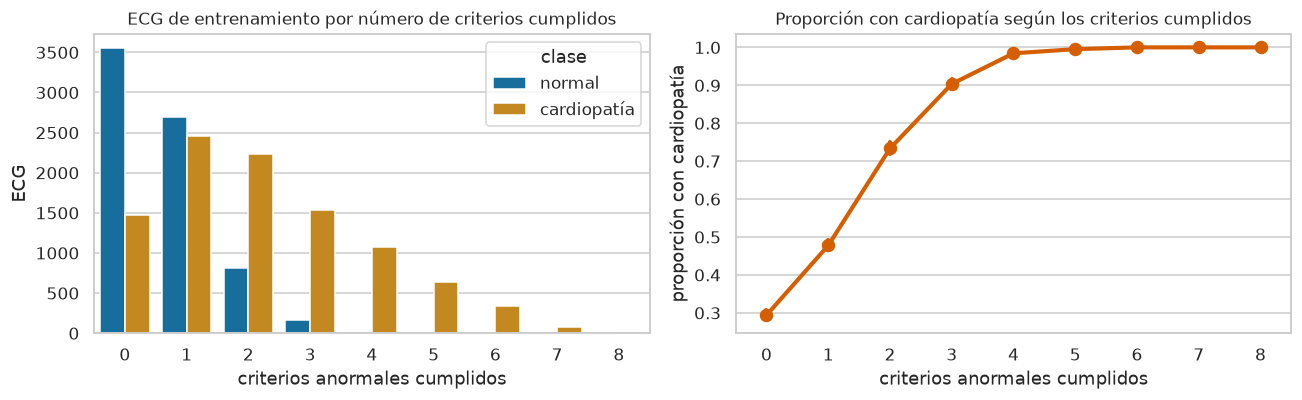

,AUROC,AUPRC,sens_con_esp_90,esp_con_sens_95
entrenamiento,0.785,0.818,0.373,0.0
validación,0.782,0.818,0.385,0.0


ECG de entrenamiento con cardiopatía que no cumplen ningún criterio: 15.0% | normales que cumplen al menos uno: 50.9%


In [5]:
RULE = {
    "QRS de 110 ms o más": data.qrs_class > 0,
    "QTc de 450 ms o más": data.qtc_class > 0,
    "Alguna onda Q patológica": data.q_patho_class > 0,
    "Alguna onda T invertida": data.t_inverted_any == 1,
    "Eje del QRS fuera de -30° a 90°": data[["axis_class_izquierda", "axis_class_derecha", "axis_class_extrema"]].sum(axis=1) > 0,
    "Frecuencia menor de 60 o de 100 lpm o más": data.hr_class != 0.5,
    "Transición de la onda R temprana o tardía": data[["r_transition_class_temprana", "r_transition_class_tardia"]].sum(axis=1) > 0,
    "Sin onda P medible": data.flag_no_p_wave == 1,
}
rule_flags = pd.DataFrame(RULE).astype(int)
rule_score = rule_flags.sum(axis=1)
display(pd.DataFrame({"ECG_normales_que_lo_cumplen_%": 100 * rule_flags[train & (y == 0)].mean(),
                      "ECG_con_cardiopatia_que_lo_cumplen_%": 100 * rule_flags[train & (y == 1)].mean()}).round(1))

by_count = pd.DataFrame({"criterios": rule_score[train], "cardiopatía": y[train]})
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(data=by_count, x="criterios", hue="cardiopatía", ax=axes[0])
axes[0].set(title="ECG de entrenamiento por número de criterios cumplidos", xlabel="criterios anormales cumplidos", ylabel="ECG")
axes[0].legend(title="clase", labels=["normal", "cardiopatía"])
sns.pointplot(data=by_count, x="criterios", y="cardiopatía", errorbar=("ci", 95), ax=axes[1], color="C3")
axes[1].set(title="Proporción con cardiopatía según los criterios cumplidos", xlabel="criterios anormales cumplidos", ylabel="proporción con cardiopatía")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"entrenamiento": summarize(y[train], rule_score[train]), "validación": summarize(y[val], rule_score[val])}).T.round(3))
print(f"ECG de entrenamiento con cardiopatía que no cumplen ningún criterio: {100 * (rule_score[train & (y == 1)] == 0).mean():.1f}% | "
      f"normales que cumplen al menos uno: {100 * (rule_score[train & (y == 0)] > 0).mean():.1f}%")

La regla clínica muestra que el problema es viable: sin ningún aprendizaje ya separa las clases mucho mejor que el azar, con AUROC de 0.785 en entrenamiento y 0.782 en validación. La proporción con cardiopatía sube de 29% entre los ECG que no cumplen ningún criterio a 90% con tres criterios y a más de 98% con cuatro o más.

Pero como herramienta de tamizaje se queda corta, por dos motivos que se ven en la tabla de criterios:

- Hay criterios que casi no distinguen. La frecuencia fuera de 60 a 100 lpm aparece en el 24.0% de los normales y en el 26.1% de las cardiopatías. La transición anormal de la onda R aparece en el 19.1% de los normales. Otros son muy específicos: la onda T invertida aparece en el 0.2% de los normales y en el 29.4% de las cardiopatías.
- El 15.0% de los ECG con cardiopatía no cumple ningún criterio. Para detectar el 95% habría que derivar a todos, y por eso su especificidad con 95% de sensibilidad es 0. Con el presupuesto de 10% de normales derivados detecta solo el 37.3% de las cardiopatías en entrenamiento y el 38.5% en validación.

## 4. ¿Qué algoritmo usar como baseline?

Elegimos una regresión logística. Las razones vienen de las características del problema y de lo que mostró el Avance 2:

- Datos estructurados. Después del Avance 2 cada ECG es una fila con 111 columnas numéricas, sin faltantes, transformadas para reducir la asimetría y estandarizadas. Es el formato para el que está pensada la regresión logística; no hace falta un modelo que aprenda de la señal cruda.
- Cantidad de datos. Con 17,083 ECG de entrenamiento y 111 características hay unos 150 ECG por parámetro, suficiente para estimar un modelo lineal sin que memorice los datos.
- Características relevantes. Las variables ya resumen lo que un cardiólogo mira (duración del QRS, ST, ondas Q, voltaje). Después de la transformación del Avance 2, la correlación lineal describe bien las relaciones entre ellas (la diferencia media entre Pearson y Spearman bajó de 0.061 a 0.021), que es el supuesto con el que trabaja un modelo lineal.
- Interpretabilidad. Las características continuas están estandarizadas y las demás van de 0 a 1, así que los coeficientes son comparables: cada uno dice cuánto cambia el log-odds de cardiopatía por una desviación estándar (o al pasar de 0 a 1). Para presentar el modelo a un cardiólogo esto importa tanto como el desempeño.
- Probabilidades y umbral. La regresión logística entrega probabilidades, y el servicio necesita elegir un umbral según su capacidad de revisión.
- Balance de clases. En PTB-XL hay 58% de cardiopatía, un desbalance leve, así que no hace falta reponderar las clases para entrenar. El desbalance real del tamizaje se trata en la métrica y en el umbral, no en el entrenamiento.

Como contraste incluimos otros modelos simples y uno más complejo:

| Modelo | Papel en la comparación |
| --- | --- |
| Azar (`DummyClassifier`) | Piso absoluto: predice la prevalencia de entrenamiento para todos. |
| Regla clínica | Lo que se logra sin aprendizaje automático. |
| Solo edad y sexo | Muestra el atajo de los metadatos: en PTB-XL la edad predice la etiqueta por cómo se reunió el conjunto, no por el ECG. No es un candidato. |
| Árbol de decisión de profundidad 4 | El otro modelo interpretable clásico. |
| Regresión logística | El baseline propuesto. |
| Gradient boosting (`HistGradientBoostingClassifier`) | Un modelo no lineal más complejo, como referencia de cuánto margen dejan los métodos simples. Queda para la siguiente fase. |

### Regularización

La regresión logística tiene un hiperparámetro principal, `C`, el inverso de la fuerza de la regularización L2: con `C` pequeño los coeficientes se encogen hacia cero (modelo más simple), con `C` grande se ajustan más a los datos. Lo elegimos con la validación cruzada de ocho pliegues y la regla de un error estándar: entre los valores cuyo AUROC medio queda a menos de un error estándar del mejor, tomamos el más regularizado. Así no elegimos un modelo más complejo por una diferencia que está dentro del ruido.

,mean,std,error_estandar,AUROC_entrenamiento
C,,,,
0.001000,0.9197,0.0056,0.0020,0.9209
0.003162,0.9251,0.0051,0.0018,0.9268
0.010000,0.9296,0.0047,0.0017,0.9319
0.031623,0.9332,0.0044,0.0016,0.9360
0.100000,0.9353,0.0043,0.0015,0.9386
0.316228,0.9362,0.0043,0.0015,0.9397
1.000000,0.9364,0.0044,0.0015,0.9401
3.162278,0.9365,0.0044,0.0016,0.9402
10.000000,0.9365,0.0044,0.0016,0.9402


Mejor AUROC medio: C = 10 (0.9365) | regla de un error estándar: C = 0.1 (0.9353)


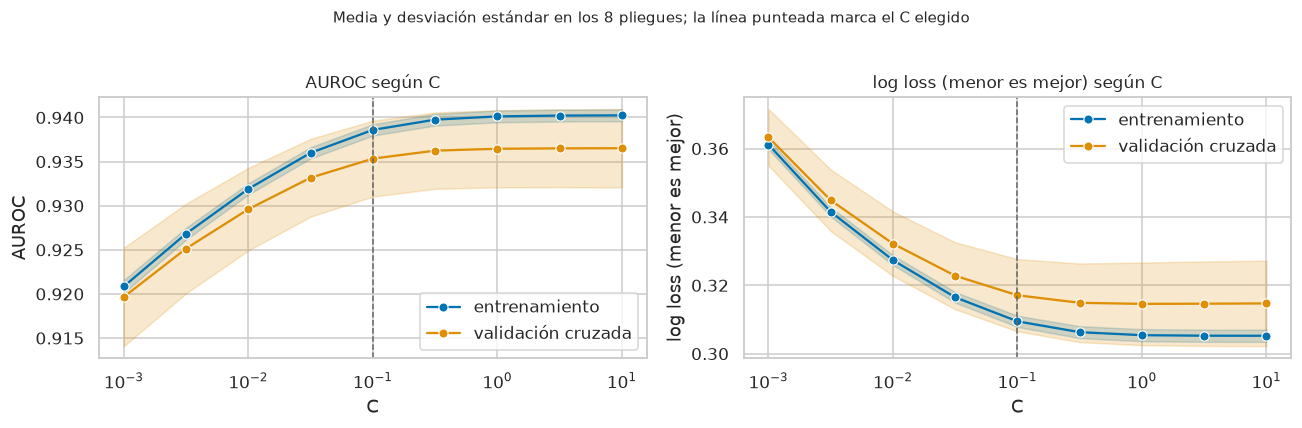

In [6]:
C_GRID = np.logspace(-3, 1, 9)
curve_rows = []
for C in C_GRID:
    scores = cross_validate(LogisticRegression(C=C, max_iter=5000), X[train], y[train], cv=CV, n_jobs=N_JOBS,
                            scoring={"AUROC": "roc_auc", "log_loss": "neg_log_loss"}, return_train_score=True)
    for fold in range(CV.get_n_splits()):
        for part, name in (("train", "entrenamiento"), ("test", "validación cruzada")):
            curve_rows.append({"C": C, "pliegue": fold, "conjunto": name, "AUROC": scores[f"{part}_AUROC"][fold], "log_loss": -scores[f"{part}_log_loss"][fold]})
c_curve = pd.DataFrame(curve_rows)

cv_auroc = c_curve[c_curve.conjunto == "validación cruzada"].groupby("C").AUROC.agg(["mean", "std"])
cv_auroc["error_estandar"] = cv_auroc["std"] / np.sqrt(CV.get_n_splits())
best = cv_auroc["mean"].idxmax()
C_BEST = float(cv_auroc.index[cv_auroc["mean"] >= cv_auroc.loc[best, "mean"] - cv_auroc.loc[best, "error_estandar"]].min())
gap = c_curve.groupby(["C", "conjunto"]).AUROC.mean().unstack()
display(pd.concat([cv_auroc, gap["entrenamiento"].rename("AUROC_entrenamiento")], axis=1).round(4))
print(f"Mejor AUROC medio: C = {best:g} ({cv_auroc.loc[best, 'mean']:.4f}) | regla de un error estándar: C = {C_BEST:g} ({cv_auroc.loc[C_BEST, 'mean']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, label in ((axes[0], "AUROC", "AUROC"), (axes[1], "log_loss", "log loss (menor es mejor)")):
    sns.lineplot(data=c_curve, x="C", y=metric, hue="conjunto", marker="o", errorbar="sd", ax=ax)
    ax.axvline(C_BEST, color="0.4", linestyle="--", linewidth=1)
    ax.set(xscale="log", ylabel=label, title=f"{label} según C")
    ax.legend(title="")
fig.suptitle("Media y desviación estándar en los 8 pliegues; la línea punteada marca el C elegido", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

El AUROC de validación cruzada sube de 0.920 con `C = 0.001` hasta estabilizarse en 0.9365 a partir de `C = 1`. El máximo está en `C = 10`, pero la diferencia con `C = 0.1` (0.9353) es menor que un error estándar (0.0016), así que la regla elige `C = 0.1`.

La brecha entre entrenamiento y validación cruzada es pequeña en todo el recorrido: de 0.001 con la regularización más fuerte a 0.004 con la más débil. Es decir, la regularización no está conteniendo un sobreajuste. Lo que hace una regularización fuerte es bajar las dos curvas a la vez, que es la forma del subajuste. El log loss sigue el mismo patrón.

## 5. Comparación con las referencias

Cada modelo se evalúa con sus predicciones out-of-fold en los ocho pliegues de entrenamiento y, ya entrenado con todo el entrenamiento, en el pliegue 9 de validación.

validación cruzada                         \
                                               AUROC  AUPRC sens_con_esp_90   
Azar                                           0.491  0.570           0.000   
Regla clínica                                  0.785  0.818           0.373   
Solo edad y sexo                               0.715  0.731           0.210   
Árbol de decisión (profundidad 4)              0.880  0.922           0.767   
Regresión logística (baseline)                 0.935  0.957           0.826   
Gradient boosting (referencia)                 0.955  0.969           0.868   

                                                                       \
                                  esp_con_sens_95 AUROC_desv_pliegues   
Azar                                        0.000               0.000   
Regla clínica                               0.000               0.009   
Solo edad y sexo                            0.253               0.010   
Árbol de decisión (profundidad 4)           0.195               0.004   
Regresión logística (baseline)              0.620               0.004   
Gradient boosting (referencia)              0.740               0.004   

                                  validación (pliegue 9)         \
                                                   AUROC  AUPRC   
Azar                                               0.500  0.574   
Regla clínica                                      0.782  0.818   
Solo edad y sexo                                   0.729  0.752   
Árbol de decisión (profundidad 4)                  0.866  0.893   
Regresión logística (baseline)                     0.928  0.951   
Gradient boosting (referencia)                     0.943  0.961   

                                                                   
                                  sens_con_esp_90 esp_con_sens_95  
Azar                                        0.000           0.000  
Regla clínica                               0.385           0.000  
Solo edad y sexo                            0.155           0.222  
Árbol de decisión (profundidad 4)           0.729           0.000  
Regresión logística (baseline)              0.804           0.566  
Gradient boosting (referencia)              0.843           0.662

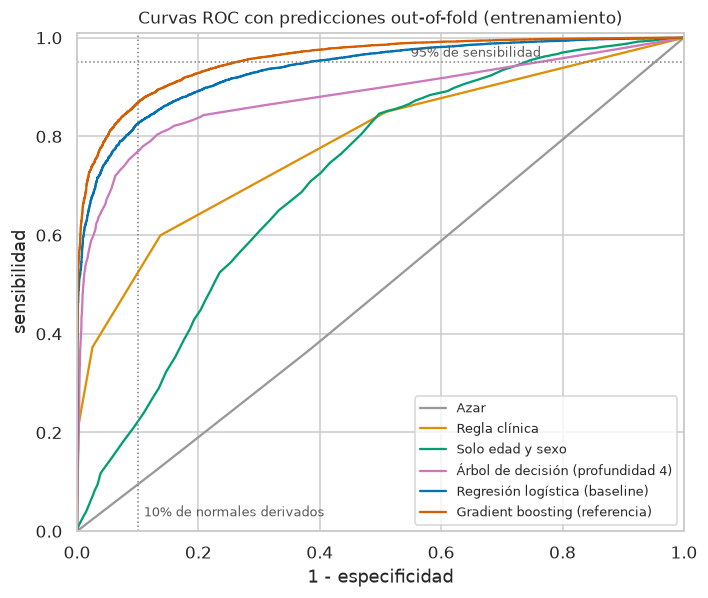

In [7]:
def baseline_model() -> LogisticRegression:
    return LogisticRegression(C=C_BEST, max_iter=5000)


MODELS = {
    "Azar": (DummyClassifier(strategy="prior"), FEATURES),
    "Solo edad y sexo": (LogisticRegression(max_iter=5000), METADATA),
    "Árbol de decisión (profundidad 4)": (DecisionTreeClassifier(max_depth=4, random_state=SEED), FEATURES),
    "Regresión logística (baseline)": (baseline_model(), FEATURES),
    "Gradient boosting (referencia)": (HistGradientBoostingClassifier(random_state=SEED), FEATURES),
}
oof, val_score, fitted = {"Regla clínica": rule_score[train].to_numpy(dtype=float)}, {"Regla clínica": rule_score[val].to_numpy(dtype=float)}, {}
for name, (model, columns) in MODELS.items():
    oof[name] = cross_val_predict(clone(model), data.loc[train, columns], y[train], cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    fitted[name] = clone(model).fit(data.loc[train, columns], y[train])
    val_score[name] = fitted[name].predict_proba(data.loc[val, columns])[:, 1]

ORDER = ["Azar", "Regla clínica", "Solo edad y sexo", "Árbol de decisión (profundidad 4)", "Regresión logística (baseline)", "Gradient boosting (referencia)"]
fold_train = folds[train].to_numpy()
comparison = pd.concat({
    "validación cruzada": pd.DataFrame({n: summarize(y[train], oof[n]) for n in ORDER}).T.assign(
        AUROC_desv_pliegues=[np.std([roc_auc_score(y[train][fold_train == f], oof[n][fold_train == f]) for f in np.unique(fold_train)]) for n in ORDER]),
    "validación (pliegue 9)": pd.DataFrame({n: summarize(y[val], val_score[n]) for n in ORDER}).T,
}, axis=1)
display(comparison.round(3))

roc_rows = []
for name in ORDER:
    fpr, tpr, _ = roc_curve(y[train], oof[name])
    roc_rows.append(pd.DataFrame({"modelo": name, "1 - especificidad": fpr, "sensibilidad": tpr}))
fig, ax = plt.subplots(figsize=(6.6, 5.6))
MODEL_COLORS = dict(zip(ORDER, ["0.6", "C1", "C2", "C4", "C0", "C3"]))
sns.lineplot(data=pd.concat(roc_rows), x="1 - especificidad", y="sensibilidad", hue="modelo", hue_order=ORDER, palette=MODEL_COLORS, estimator=None, sort=False, errorbar=None, ax=ax)
ax.axvline(0.10, color="0.5", linestyle=":", linewidth=1)
ax.axhline(0.95, color="0.5", linestyle=":", linewidth=1)
ax.text(0.11, 0.03, "10% de normales derivados", fontsize=8.5, color="0.35")
ax.text(0.55, 0.955, "95% de sensibilidad", fontsize=8.5, color="0.35", va="bottom")
ax.set(title="Curvas ROC con predicciones out-of-fold (entrenamiento)", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(title="", fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()

La regresión logística supera con amplitud a todas las referencias simples:

- Frente a la regla clínica, el AUROC pasa de 0.785 a 0.935 en validación cruzada y de 0.782 a 0.928 en el pliegue 9. Con el presupuesto de 10% de normales derivados detecta el 82.6% de las cardiopatías, contra 37.3% de la regla.
- Frente al árbol de decisión de profundidad 4, que también es interpretable, gana 0.055 de AUROC (0.935 contra 0.880). Con profundidad 4 el árbol tiene como máximo 16 hojas, así que solo puede dar 16 puntuaciones distintas. Por eso su especificidad con 95% de sensibilidad es 0.195 en validación cruzada y 0 en el pliegue 9.
- La edad y el sexo solos llegan a 0.715. Es el atajo de PTB-XL que el Avance 2 dejó fuera, y queda muy por debajo de lo que aporta la señal.
- El azar da 0.491 y no exactamente 0.5 porque la constante que predice cambia un poco de un pliegue a otro. En el pliegue 9, donde la constante es una sola, da 0.500.

Gradient boosting es el único modelo por encima del baseline: 0.955 contra 0.935 en validación cruzada y 0.943 contra 0.928 en el pliegue 9. Con 95% de sensibilidad deja sin derivar al 74.0% de los normales, contra el 62.0% del baseline. La variación entre pliegues del baseline es pequeña (desviación de 0.004 en el AUROC), así que estas diferencias no son ruido de un pliegue en particular.

## 6. ¿Qué características importan?

El Avance 2 ya aplicó métodos de filtro (varianza, ANOVA, chi-cuadrado y correlación) para llegar a 111 características. Ahora que hay un modelo, medimos la importancia de cada una con tres familias de métodos que sí usan el modelo:

- Embebidos: los coeficientes de la regresión logística y la regularización L1, que lleva a cero los coeficientes de las variables que no aportan.
- Permutación: cuánto baja el AUROC de validación si desordenamos una característica (o una familia completa) y rompemos su relación con la etiqueta.
- Wrapper: eliminación recursiva de características (RFE), que reentrena el modelo quitando cada vez la característica menos útil y mide el AUROC con validación cruzada.

### Coeficientes

Ajustamos el baseline en cada uno de los ocho subconjuntos de la validación cruzada para ver si los coeficientes son estables. Una barra larga con poca variación entre pliegues indica una característica en la que el modelo se apoya de forma consistente.

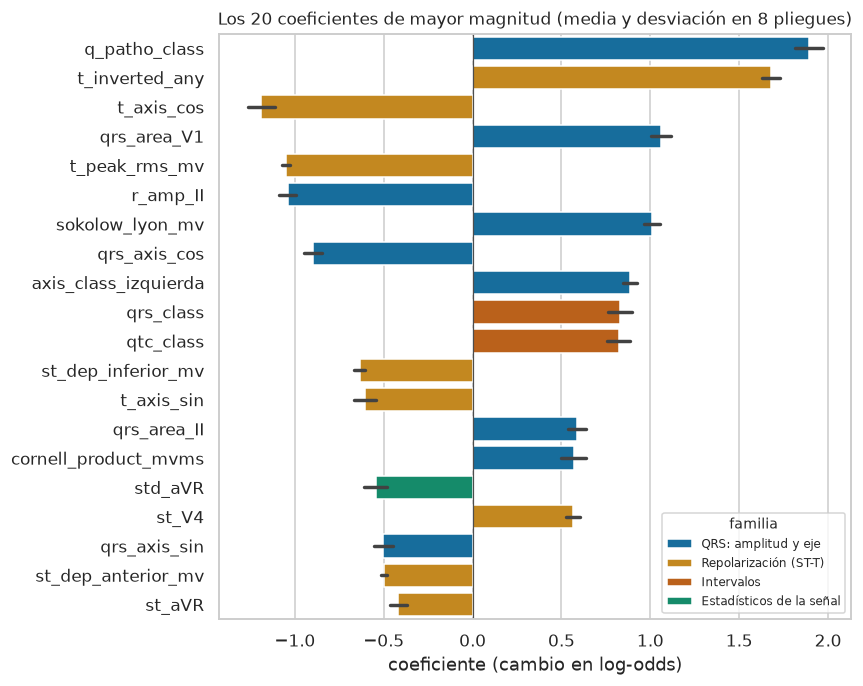

Características con coeficiente que cambia de signo entre pliegues: 15 de 111


,coeficiente,desv_entre_pliegues,familia,cambia_de_signo
q_patho_class,1.978,0.078,QRS: amplitud y eje,False
t_inverted_any,1.777,0.050,Repolarización (ST-T),False
t_axis_cos,-1.239,0.077,Repolarización (ST-T),False
qrs_area_V1,1.100,0.055,QRS: amplitud y eje,False
t_peak_rms_mv,-1.085,0.023,Repolarización (ST-T),False
r_amp_II,-1.071,0.048,QRS: amplitud y eje,False
sokolow_lyon_mv,1.043,0.044,QRS: amplitud y eje,False
qrs_axis_cos,-0.927,0.050,QRS: amplitud y eje,False
axis_class_izquierda,0.891,0.039,QRS: amplitud y eje,False
qrs_class,0.878,0.067,Intervalos,False


In [8]:
cv_fits = cross_validate(baseline_model(), X[train], y[train], cv=CV, n_jobs=N_JOBS, return_estimator=True)["estimator"]
coef_folds = pd.DataFrame([m.coef_[0] for m in cv_fits], columns=FEATURES)
final_full = fitted["Regresión logística (baseline)"]
coefficients = pd.DataFrame({"coeficiente": final_full.coef_[0], "desv_entre_pliegues": coef_folds.std(), "familia": FAMILY[FEATURES]}, index=FEATURES)
coefficients["cambia_de_signo"] = (np.sign(coef_folds).nunique() > 1).to_numpy()
top_coef = coefficients.coeficiente.abs().sort_values(ascending=False).index[:20]

long = coef_folds[top_coef].melt(var_name="característica", value_name="coeficiente").assign(familia=lambda d: d["característica"].map(FAMILY))
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.barplot(data=long, y="característica", x="coeficiente", hue="familia", palette=FAMILY_COLORS, errorbar="sd", dodge=False, ax=ax)
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set(title="Los 20 coeficientes de mayor magnitud (media y desviación en 8 pliegues)", xlabel="coeficiente (cambio en log-odds)", ylabel="")
ax.legend(title="familia", fontsize=8, title_fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()
print(f"Características con coeficiente que cambia de signo entre pliegues: {int(coefficients.cambia_de_signo.sum())} de {len(FEATURES)}")
display(coefficients.loc[top_coef].round(3))

Los coeficientes son estables: ninguno de los 20 más grandes cambia de signo entre pliegues y su desviación entre pliegues es como máximo 0.078. En total, 15 de las 111 características tienen un coeficiente que cambia de signo según el subconjunto de entrenamiento; son las de peso cercano a cero.

Los coeficientes más grandes corresponden a variables binarias u ordinales, que se miden de 0 a 1: tener alguna onda Q patológica (`q_patho_class`, +1.98) o alguna onda T invertida (`t_inverted_any`, +1.78). Le siguen el eje de la onda T (`t_axis_cos`, -1.24), el área del QRS en V1 (+1.10), la amplitud de la onda T (`t_peak_rms_mv`, -1.08), la onda R en II (-1.07) y el índice de Sokolow-Lyon (+1.04). Entre los 20 hay 9 del QRS, 8 de repolarización, 2 de intervalos (`qrs_class`, `qtc_class`) y 1 estadístico (`std_aVR`).

El signo coincide con lo esperado donde la clínica da una dirección clara: las ondas Q patológicas, las ondas T invertidas, el QRS ancho, el QT largo y el voltaje de hipertrofia aumentan la probabilidad de cardiopatía. El signo negativo de `t_peak_rms_mv` es coherente con lo que mostró el perfil del Avance 2, donde la onda T en V5 bajaba en `STTC`.

### Importancia por permutación

Los coeficientes tienen una limitación: si dos características están correlacionadas, el modelo puede repartir el peso entre ellas de forma arbitraria, una con signo positivo y otra con negativo. La importancia por permutación mide directamente cuánto depende el desempeño de cada variable. La calculamos en el pliegue 9 de validación, con 20 permutaciones por variable, y también por familia: se desordenan juntas todas las columnas de una familia, lo que evita que una variable correlacionada compense a otra.

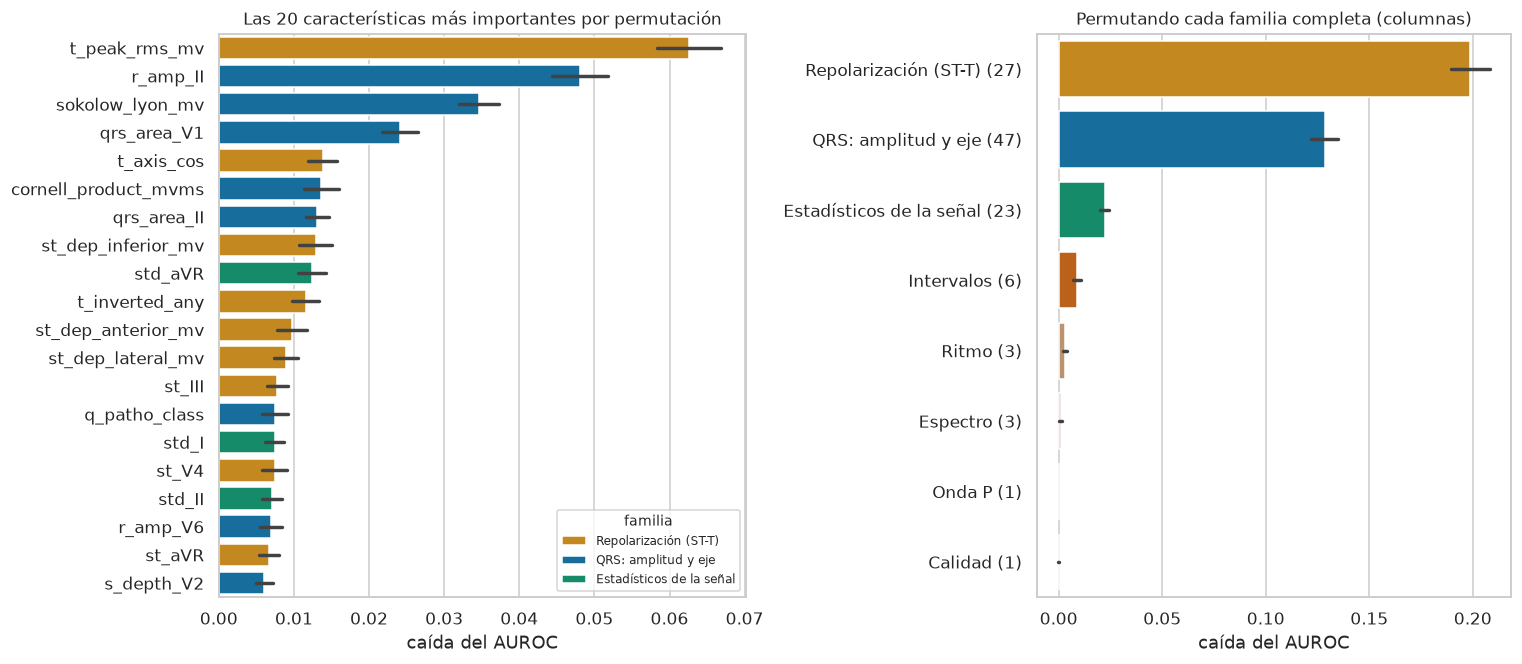

AUROC del baseline en validación: 0.9280
Características cuya permutación no baja el AUROC (caída media <= 0): 11 de 111


,mean,std
familia,,
Repolarización (ST-T),0.1989,0.0094
QRS: amplitud y eje,0.1285,0.0065
Estadísticos de la señal,0.0222,0.0022
Intervalos,0.0090,0.0020
Ritmo,0.0031,0.0008
Espectro,0.0009,0.0006
Onda P,0.0001,0.0001
Calidad,-0.0001,0.0001


,caida_AUROC,puesto_permutacion,coeficiente,puesto_coeficiente,ECG_train_con_valor_distinto_de_0_%
t_peak_rms_mv,0.0626,1,-1.0849,5,100.0000
r_amp_II,0.0481,2,-1.0713,6,100.0000
sokolow_lyon_mv,0.0346,3,1.0433,7,100.0000
qrs_area_V1,0.0242,4,1.1004,4,100.0000
t_axis_cos,0.0138,5,-1.2388,3,100.0000
cornell_product_mvms,0.0136,6,0.5829,15,100.0000
qrs_area_II,0.0131,7,0.6223,14,100.0000
st_dep_inferior_mv,0.0129,8,-0.6519,12,100.0000
std_aVR,0.0124,9,-0.5734,16,100.0000
t_inverted_any,0.0115,10,1.7767,2,17.0228


In [9]:
X_val, y_val = X[val], y[val]
single = permutation_importance(final_full, X_val, y_val, scoring="roc_auc", n_repeats=20, random_state=SEED, n_jobs=N_JOBS)
permutation = pd.DataFrame({"caida_AUROC": single.importances_mean, "desv": single.importances_std, "familia": FAMILY[FEATURES]}, index=FEATURES)

base_auroc = roc_auc_score(y_val, final_full.predict_proba(X_val)[:, 1])
rng = np.random.default_rng(SEED)
group_rows = []
for family in FAMILIES:
    columns = list(FAMILY.index[FAMILY == family])
    for _ in range(20):
        shuffled = X_val.copy()
        shuffled[columns] = X_val[columns].to_numpy()[rng.permutation(len(X_val))]
        group_rows.append({"familia": family, "columnas": len(columns), "caida_AUROC": base_auroc - roc_auc_score(y_val, final_full.predict_proba(shuffled)[:, 1])})
by_family = pd.DataFrame(group_rows)
family_order = by_family.groupby("familia").caida_AUROC.mean().sort_values(ascending=False).index

top_perm = permutation.caida_AUROC.sort_values(ascending=False).index[:20]
long = pd.DataFrame(single.importances[[FEATURES.index(c) for c in top_perm]].T, columns=top_perm).melt(var_name="característica", value_name="caída del AUROC")
long["familia"] = long["característica"].map(FAMILY)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), width_ratios=[1, 0.9])
sns.barplot(data=long, y="característica", x="caída del AUROC", hue="familia", palette=FAMILY_COLORS, errorbar="sd", dodge=False, ax=axes[0])
axes[0].set(title="Las 20 características más importantes por permutación", ylabel="")
axes[0].legend(title="familia", fontsize=8, title_fontsize=9, loc="lower right")
sns.barplot(data=by_family, y="familia", x="caida_AUROC", order=family_order, hue="familia", palette=FAMILY_COLORS, errorbar="sd", legend=False, ax=axes[1])
axes[1].set_yticks(range(len(family_order)), [f"{f} ({int((FAMILY == f).sum())})" for f in family_order])
axes[1].set(title="Permutando cada familia completa (columnas)", xlabel="caída del AUROC", ylabel="")
plt.tight_layout()
plt.show()
print(f"AUROC del baseline en validación: {base_auroc:.4f}")
print(f"Características cuya permutación no baja el AUROC (caída media <= 0): {int((permutation.caida_AUROC <= 0).sum())} de {len(FEATURES)}")
display(by_family.groupby("familia").caida_AUROC.agg(["mean", "std"]).loc[family_order].round(4))
coef_rank = coefficients.coeficiente.abs().rank(ascending=False).astype(int)
perm_rank = permutation.caida_AUROC.rank(ascending=False).astype(int)
shown = list(top_perm[:10]) + [c for c in top_coef[:3] if c not in top_perm[:10]]
display(pd.DataFrame({"caida_AUROC": permutation.caida_AUROC, "puesto_permutacion": perm_rank, "coeficiente": coefficients.coeficiente,
                      "puesto_coeficiente": coef_rank, "ECG_train_con_valor_distinto_de_0_%": 100 * (X[train] != 0).mean()}).loc[shown].round(4))

La permutación confirma que el modelo depende sobre todo de la repolarización y del QRS. Al desordenar la familia de repolarización el AUROC de validación cae 0.199, y con la del QRS cae 0.129. Le siguen los estadísticos de la señal (0.022) y los intervalos (0.009). Ritmo, espectro, onda P y calidad aportan menos de 0.004 cada una. En 11 de las 111 características la permutación no baja el AUROC.

Por característica, las más importantes son la amplitud de la onda T (`t_peak_rms_mv`, caída de 0.063), la onda R en II (0.048) y Sokolow-Lyon (0.035).

Los dos métodos no ordenan igual. `q_patho_class` tiene el mayor coeficiente y queda en el puesto 14 por permutación (0.0075); `t_inverted_any` es segunda por coeficiente y décima por permutación. Las dos valen 0 en la mayoría de los ECG (solo el 24.9% y el 17.0% tienen un valor distinto de cero): cuando aparecen pesan mucho, pero aparecen poco. La permutación mide el efecto sobre toda la población, que es lo que importa para decidir si una variable se conserva.

### Regularización L1

Con penalización L1 el modelo pone exactamente en cero los coeficientes de las variables que no necesita, y cuanto más fuerte es la penalización, menos variables conserva. Recorremos la fuerza de la penalización y medimos con validación cruzada cuántas variables quedan y cuánto AUROC se conserva.

In [10]:
l1_rows = []
for C in [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.3, 1.0]:
    scores = cross_validate(LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=3000, random_state=SEED), X[train], y[train], cv=CV,
                            scoring="roc_auc", n_jobs=N_JOBS, return_estimator=True)
    l1_rows.append({"C": C, "AUROC_validación_cruzada": scores["test_score"].mean(), "desv": scores["test_score"].std(),
                    "características_no_nulas": np.mean([np.count_nonzero(m.coef_) for m in scores["estimator"]])})
l1_path = pd.DataFrame(l1_rows)
display(l1_path.round(4))

,C,AUROC_validación_cruzada,desv,características_no_nulas
0,0.002,0.9025,0.0055,14.750
1,0.005,0.9116,0.0059,28.375
2,0.010,0.9194,0.0057,42.875
3,0.020,0.9271,0.0048,51.000
4,0.050,0.9322,0.0045,70.625
5,0.100,0.9345,0.0042,88.875
6,0.300,0.9361,0.0041,102.500
7,1.000,0.9365,0.0041,107.000


### Eliminación recursiva de características (wrapper)

RFE parte de las 111 características, entrena el modelo, quita la de menor coeficiente en valor absoluto y repite. Con validación cruzada (`RFECV`) mide el AUROC para cada número de características. Para elegir cuántas conservar usamos otra vez la regla de un error estándar: el menor número de características cuyo AUROC queda a menos de un error estándar del mejor. Si el conjunto reducido iguala al completo, nos quedamos con el reducido, porque es más simple y las características que sobran solo añaden ruido.

RFECV en 12 s | máximo: 98 características (AUROC 0.9354) | regla de un error estándar: 50 características (AUROC 0.9341)


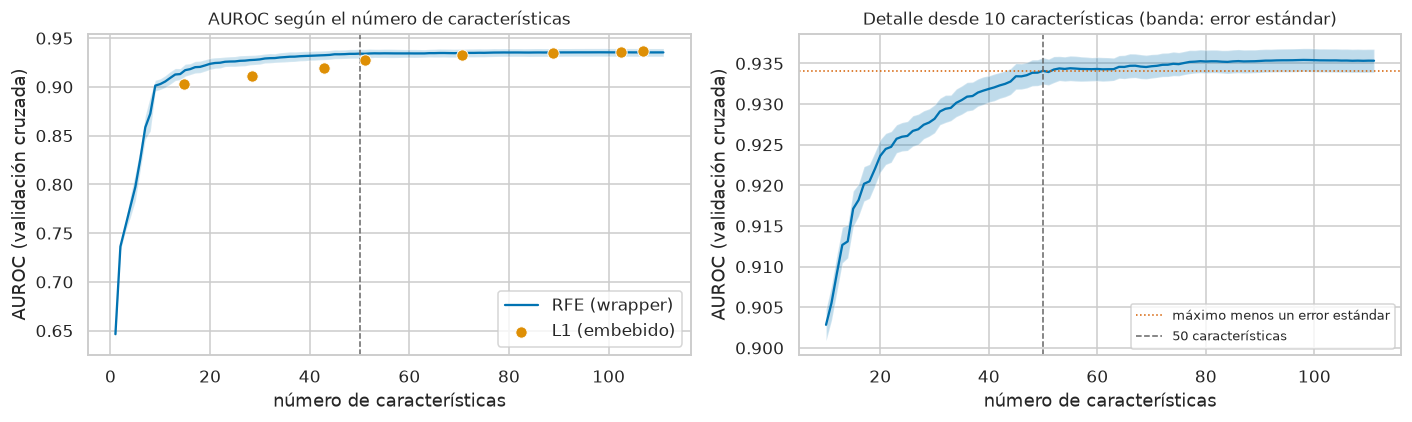

,mean_test_score,std_test_score
n_features,,
1,0.6463,0.0065
5,0.7974,0.0140
10,0.9028,0.0055
20,0.9236,0.0057
30,0.9282,0.0049
40,0.9319,0.0046
50,0.9341,0.0046
75,0.9349,0.0041
98,0.9354,0.0040


,construidas,conservadas_por_RFE,conservadas_%
familia,,,
QRS: amplitud y eje,47,26,55.0
Repolarización (ST-T),27,17,63.0
Estadísticos de la señal,23,3,13.0
Intervalos,6,3,50.0
Espectro,3,0,0.0
Ritmo,3,1,33.0
Calidad,1,0,0.0
Onda P,1,0,0.0


In [11]:
start = time.perf_counter()
rfecv = RFECV(baseline_model(), step=1, cv=CV, scoring="roc_auc", min_features_to_select=1, n_jobs=N_JOBS).fit(X[train], y[train])
rfe_curve = pd.DataFrame({k: rfecv.cv_results_[k] for k in ("n_features", "mean_test_score", "std_test_score")})
rfe_curve["error_estandar"] = rfe_curve.std_test_score / np.sqrt(CV.get_n_splits())
peak = rfe_curve.loc[rfe_curve.mean_test_score.idxmax()]
N_SELECTED = int(rfe_curve.loc[rfe_curve.mean_test_score >= peak.mean_test_score - peak.error_estandar, "n_features"].min())
rfe = RFE(baseline_model(), n_features_to_select=N_SELECTED, step=1).fit(X[train], y[train])
SELECTED = [c for c, keep in zip(FEATURES, rfe.support_) if keep]
print(f"RFECV en {time.perf_counter() - start:.0f} s | máximo: {int(peak.n_features)} características (AUROC {peak.mean_test_score:.4f}) | "
      f"regla de un error estándar: {N_SELECTED} características (AUROC {rfe_curve.set_index('n_features').loc[N_SELECTED, 'mean_test_score']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
sns.lineplot(data=rfe_curve, x="n_features", y="mean_test_score", ax=ax, label="RFE (wrapper)")
ax.fill_between(rfe_curve.n_features, rfe_curve.mean_test_score - rfe_curve.std_test_score, rfe_curve.mean_test_score + rfe_curve.std_test_score, alpha=0.2)
sns.scatterplot(data=l1_path, x="características_no_nulas", y="AUROC_validación_cruzada", ax=ax, color="C1", s=55, label="L1 (embebido)", zorder=3)
ax.axvline(N_SELECTED, color="0.4", linestyle="--", linewidth=1)
ax.set(xlabel="número de características", ylabel="AUROC (validación cruzada)", title="AUROC según el número de características")
ax.legend(title="")
ax = axes[1]
zoom = rfe_curve[rfe_curve.n_features >= 10]
sns.lineplot(data=zoom, x="n_features", y="mean_test_score", ax=ax)
ax.fill_between(zoom.n_features, zoom.mean_test_score - zoom.error_estandar, zoom.mean_test_score + zoom.error_estandar, alpha=0.25)
ax.axhline(peak.mean_test_score - peak.error_estandar, color="C3", linestyle=":", linewidth=1, label="máximo menos un error estándar")
ax.axvline(N_SELECTED, color="0.4", linestyle="--", linewidth=1, label=f"{N_SELECTED} características")
ax.set(xlabel="número de características", ylabel="AUROC (validación cruzada)", title="Detalle desde 10 características (banda: error estándar)")
ax.legend(title="", fontsize=8.5)
plt.tight_layout()
plt.show()

display(rfe_curve.set_index("n_features").loc[[1, 5, 10, 20, 30, 40, 50, 75, 98, 111], ["mean_test_score", "std_test_score"]].round(4))
kept = pd.DataFrame({"construidas": FAMILY.value_counts(), "conservadas_por_RFE": FAMILY[SELECTED].value_counts()}).fillna(0).astype(int)
kept["conservadas_%"] = (100 * kept.conservadas_por_RFE / kept.construidas).round(0)
display(kept.loc[FAMILIES])

Las dos curvas cuentan lo mismo. El AUROC sube rápido con las primeras características y después casi no cambia: con 10 características RFE alcanza 0.903, con 20 llega a 0.924, con 50 a 0.934 y con las 111 a 0.935. El máximo (0.9354, con 98) está prácticamente en el mismo valor que el modelo completo. La regla de un error estándar elige 50 características.

La regularización L1 llega a la misma meseta (0.9365 con 107 coeficientes no nulos), pero con pocas variables rinde menos que RFE: con unas 28 variables obtiene 0.912, contra 0.928 de RFE con 30.

Lo que RFE descarta coincide con la permutación. Conserva más de la mitad del QRS (26 de 47) y de la repolarización (17 de 27), pero solo 3 de los 23 estadísticos de la señal y ninguna del espectro, la calidad ni la onda P.

### ¿Sobran características?

Comparamos el baseline con las 111 características contra el mismo modelo con las seleccionadas por RFE, en validación cruzada y en el pliegue 9. La regla de decisión es la siguiente: si el intervalo de 95% de la diferencia de AUROC en el pliegue 9 (reducido menos completo) incluye el cero o es positivo, el conjunto reducido no pierde desempeño y lo adoptamos como baseline final; si queda por debajo de cero, conservamos las 111.

In [12]:
reduced = LogisticRegression(C=C_BEST, max_iter=5000)
oof["Regresión logística, características RFE"] = cross_val_predict(clone(reduced), X.loc[train, SELECTED], y[train], cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
fitted["Regresión logística, características RFE"] = clone(reduced).fit(X.loc[train, SELECTED], y[train])
val_score["Regresión logística, características RFE"] = fitted["Regresión logística, características RFE"].predict_proba(X.loc[val, SELECTED])[:, 1]

pair = ["Regresión logística (baseline)", "Regresión logística, características RFE"]
display(pd.concat({
    "validación cruzada": pd.DataFrame({n: summarize(y[train], oof[n]) for n in pair}).T,
    "validación (pliegue 9)": pd.DataFrame({n: summarize(y[val], val_score[n]) for n in pair}).T,
}, axis=1).assign(características=[len(FEATURES), len(SELECTED)]).round(3))
difference = paired_auroc_difference(patients[val.to_numpy()], y[val].to_numpy(), val_score[pair[1]], val_score[pair[0]])
print(f"Diferencia de AUROC en validación (RFE menos completo): {difference['difference']:+.4f}, IC 95% [{difference['ci_low']:+.4f}, {difference['ci_high']:+.4f}]")

dropped = [c for c in FEATURES if c not in SELECTED]
print(f"Las {len(dropped)} eliminadas por RFE explican, en conjunto, una caída por permutación de {permutation.loc[dropped, 'caida_AUROC'].sum():.4f} de AUROC en validación;")
print(f"las {len(SELECTED)} conservadas, {permutation.loc[SELECTED, 'caida_AUROC'].sum():.4f}.")

USE_REDUCED = difference["ci_high"] >= 0
FINAL_NAME = pair[1] if USE_REDUCED else pair[0]
FINAL_FEATURES = SELECTED if USE_REDUCED else FEATURES
print(f"Baseline final: {FINAL_NAME} ({len(FINAL_FEATURES)} características)")

validación cruzada         \
                                                      AUROC  AUPRC   
Regresión logística (baseline)                        0.935  0.957   
Regresión logística, características RFE              0.934  0.956   

                                                                          \
                                         sens_con_esp_90 esp_con_sens_95   
Regresión logística (baseline)                     0.826            0.62   
Regresión logística, características RFE           0.823            0.61   

                                         validación (pliegue 9)         \
                                                          AUROC  AUPRC   
Regresión logística (baseline)                            0.928  0.951   
Regresión logística, características RFE                  0.926  0.949   

                                                                          \
                                         sens_con_esp_90 esp_con_sens_95   
Regresión logística (baseline)                     0.804           0.566   
Regresión logística, características RFE           0.802           0.544   

                                         características  
                                                          
Regresión logística (baseline)                       111  
Regresión logística, características RFE              50

Diferencia de AUROC en validación (RFE menos completo): -0.0025, IC 95% [-0.0049, -0.0002]
Las 61 eliminadas por RFE explican, en conjunto, una caída por permutación de 0.0497 de AUROC en validación;
las 50 conservadas, 0.4042.
Baseline final: Regresión logística (baseline) (111 características)


Con 50 características el AUROC baja de 0.935 a 0.934 en validación cruzada y de 0.928 a 0.926 en el pliegue 9. La diferencia en validación es de -0.0025, con un intervalo de [-0.0049, -0.0002] que queda por debajo de cero. Es una pérdida muy pequeña, pero consistente, así que la regla fijada antes de ver el resultado conserva las 111 características.

Las 61 características que RFE descarta no son irrelevantes: juntas suman 0.050 de caída por permutación. Además conservarlas no cuesta sobreajuste, como se ve en la sección siguiente. El conjunto de 50 queda documentado como alternativa compacta si en los siguientes avances la simplicidad pesa más que esa diferencia.

Sobre la pregunta de si hay características que sobran: sí, pero pocas. Las 11 que no bajan el AUROC al permutarse y las familias de espectro, calidad y onda P casi no aportan a este modelo. Las del espectro y la calidad describen el registro, no al corazón, y eso es lo esperable.

## 7. ¿El modelo está sub o sobreajustado?

Comparamos cada modelo en tres conjuntos: los mismos datos con los que se entrenó (entrenamiento), la validación cruzada y el pliegue 9. Los signos que buscamos son:

- Sobreajuste: desempeño mucho mejor en entrenamiento que en los datos no vistos. El modelo memoriza particularidades de los ECG de entrenamiento.
- Subajuste: desempeño similar en los dos, pero por debajo de lo que logra un modelo más flexible con los mismos datos. El modelo es demasiado simple para la relación que hay.

Para hacer visible el contraste incluimos un árbol de decisión sin límite de profundidad, el ejemplo clásico de sobreajuste. Además del AUROC usamos el log loss y el Brier score, que miden la calidad de las probabilidades y castigan las predicciones muy seguras que resultan equivocadas.

AUROC                         \
conjunto                                 entrenamiento validación (pliegue 9)   
modelo                                                                          
Árbol de decisión (profundidad 4)                0.884                  0.866   
Árbol de decisión (sin límite)                   1.000                  0.814   
Regresión logística (baseline)                   0.939                  0.928   
Regresión logística, características RFE         0.936                  0.926   
Gradient boosting (referencia)                   0.986                  0.943   

                                                                 log_loss  \
conjunto                                 validación cruzada entrenamiento   
modelo                                                                      
Árbol de decisión (profundidad 4)                     0.880         0.386   
Árbol de decisión (sin límite)                        0.814         0.000   
Regresión logística (baseline)                        0.935         0.309   
Regresión logística, características RFE              0.934         0.316   
Gradient boosting (referencia)                        0.955         0.169   

                                                                 \
conjunto                                 validación (pliegue 9)   
modelo                                                            
Árbol de decisión (profundidad 4)                         0.423   
Árbol de decisión (sin límite)                            2.536   
Regresión logística (baseline)                            0.335   
Regresión logística, características RFE                  0.341   
Gradient boosting (referencia)                            0.303   

                                                             \
conjunto                                 validación cruzada   
modelo                                                        
Árbol de decisión (profundidad 4)                     0.394   
Árbol de decisión (sin límite)                        2.519   
Regresión logística (baseline)                        0.317   
Regresión logística, características RFE              0.319   
Gradient boosting (referencia)                        0.268   

                                                                             AUROC  
conjunto                                 brecha entrenamiento - validación cruzada  
modelo                                                                              
Árbol de decisión (profundidad 4)                                            0.004  
Árbol de decisión (sin límite)                                               0.186  
Regresión logística (baseline)                                               0.003  
Regresión logística, características RFE                                     0.002  
Gradient boosting (referencia)                                               0.031

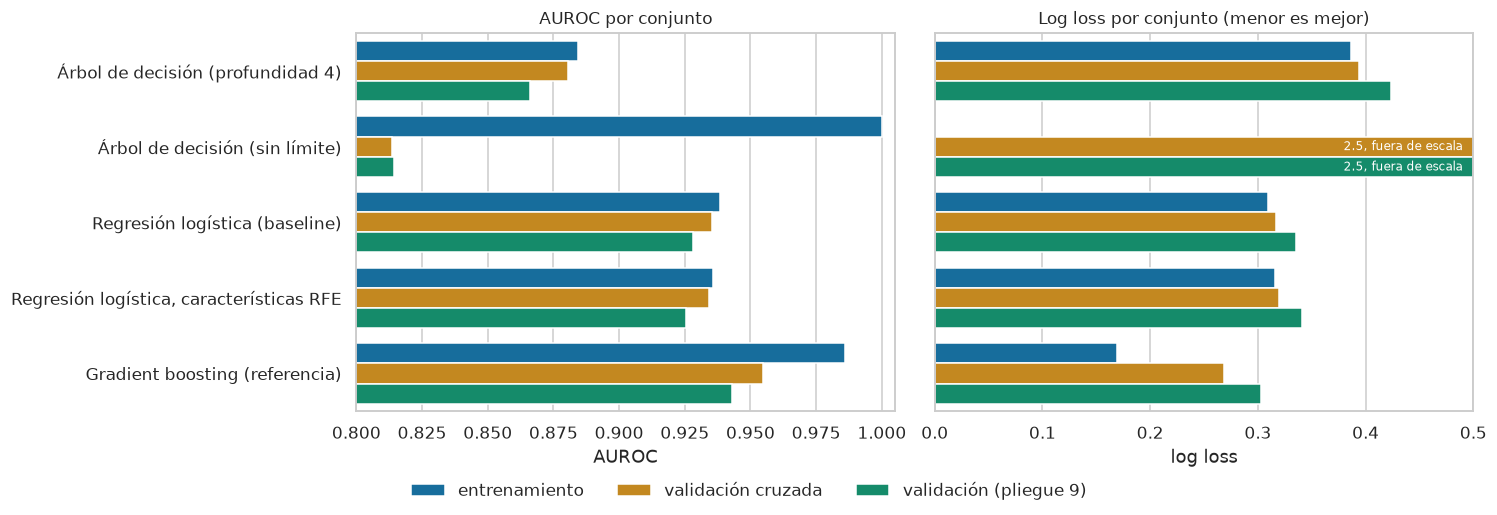

Log loss del árbol sin límite: entrenamiento 0.00 | validación cruzada 2.52 | validación (pliegue 9) 2.54


In [13]:
fit_models = {
    "Árbol de decisión (profundidad 4)": (MODELS["Árbol de decisión (profundidad 4)"][0], FEATURES),
    "Árbol de decisión (sin límite)": (DecisionTreeClassifier(random_state=SEED), FEATURES),
    "Regresión logística (baseline)": (baseline_model(), FEATURES),
    "Regresión logística, características RFE": (baseline_model(), SELECTED),
    "Gradient boosting (referencia)": (MODELS["Gradient boosting (referencia)"][0], FEATURES),
}
fit_rows = []
for name, (model, columns) in fit_models.items():
    model = fitted[name] if name in fitted else clone(model).fit(X.loc[train, columns], y[train])
    out_of_fold = oof.get(name)
    if out_of_fold is None:
        out_of_fold = cross_val_predict(clone(model), X.loc[train, columns], y[train], cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    for part, mask, score in (("entrenamiento", train, model.predict_proba(X.loc[train, columns])[:, 1]),
                              ("validación cruzada", train, out_of_fold),
                              ("validación (pliegue 9)", val, model.predict_proba(X.loc[val, columns])[:, 1])):
        clipped = np.clip(score, 1e-6, 1 - 1e-6)
        fit_rows.append({"modelo": name, "conjunto": part, "AUROC": roc_auc_score(y[mask], score),
                         "log_loss": log_loss(y[mask], clipped), "Brier": brier_score_loss(y[mask], score)})
fit_table = pd.DataFrame(fit_rows)
wide = fit_table.pivot(index="modelo", columns="conjunto", values=["AUROC", "log_loss"]).loc[list(fit_models)]
wide[("AUROC", "brecha entrenamiento - validación cruzada")] = wide[("AUROC", "entrenamiento")] - wide[("AUROC", "validación cruzada")]
display(wide.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True, layout="constrained")
sns.barplot(data=fit_table, x="AUROC", y="modelo", hue="conjunto", ax=axes[0])
axes[0].set(xlim=(0.8, 1.005), title="AUROC por conjunto", ylabel="")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend_.remove()
fig.legend(handles, labels, loc="outside lower center", ncols=3, frameon=False)
sns.barplot(data=fit_table, x="log_loss", y="modelo", hue="conjunto", ax=axes[1], legend=False)
axes[1].set(xlim=(0, 0.5), title="Log loss por conjunto (menor es mejor)", ylabel="", xlabel="log loss")
for offset in (0, 0.27):
    axes[1].text(0.49, 1 + offset, "2.5, fuera de escala", ha="right", va="center", fontsize=8, color="white")
plt.show()
print("Log loss del árbol sin límite: " + " | ".join(f"{r.conjunto} {r.log_loss:.2f}" for r in fit_table[fit_table.modelo == "Árbol de decisión (sin límite)"].itertuples()))

La tabla muestra los tres comportamientos posibles:

- Sobreajuste claro: el árbol sin límite de profundidad. Tiene AUROC de 1.000 y log loss de 0.00 en entrenamiento, pero 0.814 y 2.52 en validación cruzada. Memorizó los ECG de entrenamiento: cada hoja contiene muy pocos ECG y en datos nuevos da probabilidades de 0 o 1 que muchas veces resultan equivocadas.
- Sobreajuste moderado: gradient boosting. Pasa de 0.986 en entrenamiento a 0.955 en validación cruzada (brecha de 0.031) y su log loss sube de 0.169 a 0.268. Aun así es el que mejor generaliza.
- Sin sobreajuste: la regresión logística. Tiene 0.939 en entrenamiento y 0.935 en validación cruzada (brecha de 0.003), con log loss de 0.309 y 0.317. El árbol de profundidad 4 tampoco se sobreajusta (0.884 y 0.880), pero se queda bastante más abajo.

El baseline no se sobreajusta, pero sí muestra un subajuste leve: su desempeño en entrenamiento y en validación cruzada es casi el mismo, y los dos quedan por debajo de lo que gradient boosting logra en datos que no vio (0.955). Una relación lineal no alcanza a representar toda la información que traen las características.

El pliegue 9 queda un poco por debajo de la validación cruzada en todos los modelos: 0.928 en el baseline, 0.943 en gradient boosting y 0.866 en el árbol de profundidad 4.

### Curvas de aprendizaje

Una curva de aprendizaje muestra cómo cambian el desempeño en entrenamiento y en validación cruzada al aumentar el número de ECG de entrenamiento. Si las dos curvas se juntan en un nivel bajo, el modelo está limitado por su simplicidad (subajuste) y más datos no lo mejoran. Si quedan separadas, el modelo está sobreajustado y más datos sí le ayudarían.

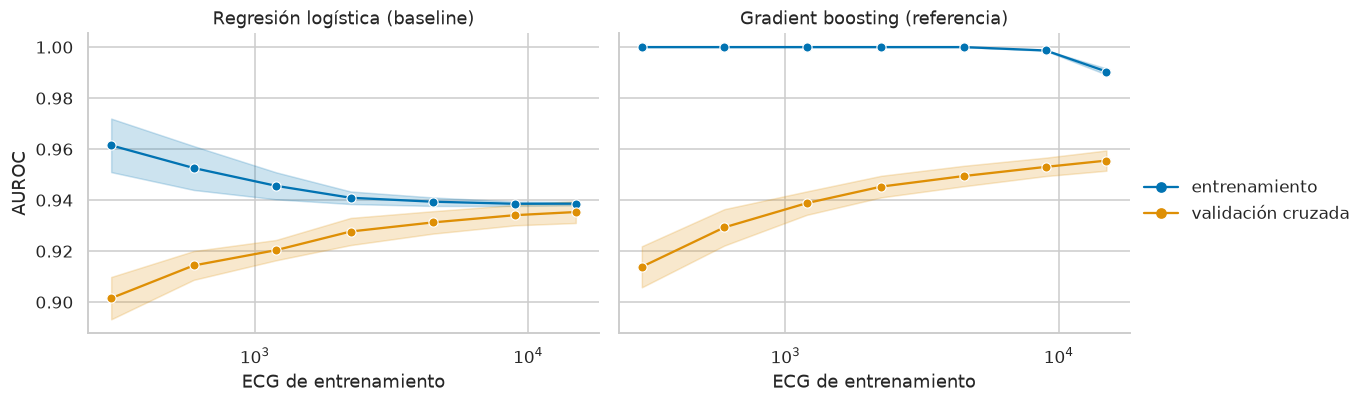

conjunto                                             entrenamiento  \
modelo                         ECG de entrenamiento                  
Gradient boosting (referencia) 298                          1.0000   
                               597                          1.0000   
                               1195                         1.0000   
                               2241                         1.0000   
                               4483                         1.0000   
                               8966                         0.9987   
                               14944                        0.9904   
Regresión logística (baseline) 298                          0.9615   
                               597                          0.9526   
                               1195                         0.9456   
                               2241                         0.9409   
                               4483                         0.9394   
                               8966                         0.9386   
                               14944                        0.9386   

conjunto                                             validación cruzada  
modelo                         ECG de entrenamiento                      
Gradient boosting (referencia) 298                               0.9138  
                               597                               0.9293  
                               1195                              0.9388  
                               2241                              0.9453  
                               4483                              0.9494  
                               8966                              0.9530  
                               14944                             0.9555  
Regresión logística (baseline) 298                               0.9015  
                               597                               0.9144  
                               1195                              0.9204  
                               2241                              0.9277  
                               4483                              0.9312  
                               8966                              0.9341  
                               14944                             0.9353

In [14]:
SIZES = [0.02, 0.04, 0.08, 0.15, 0.3, 0.6, 1.0]
learning_rows = []
for name, model, columns in ((FINAL_NAME, baseline_model(), FINAL_FEATURES), ("Gradient boosting (referencia)", HistGradientBoostingClassifier(random_state=SEED), FEATURES)):
    sizes, train_scores, cv_scores = learning_curve(model, X.loc[train, columns], y[train], cv=CV, scoring="roc_auc", train_sizes=SIZES,
                                                    shuffle=True, random_state=SEED, n_jobs=N_JOBS)
    for i, size in enumerate(sizes):
        for fold in range(train_scores.shape[1]):
            learning_rows += [{"modelo": name, "ECG de entrenamiento": size, "conjunto": "entrenamiento", "AUROC": train_scores[i, fold]},
                              {"modelo": name, "ECG de entrenamiento": size, "conjunto": "validación cruzada", "AUROC": cv_scores[i, fold]}]
learning = pd.DataFrame(learning_rows)
grid = sns.relplot(data=learning, x="ECG de entrenamiento", y="AUROC", hue="conjunto", col="modelo", kind="line", marker="o",
                   errorbar="sd", height=3.8, aspect=1.4, facet_kws={"sharey": True})
grid.set(xscale="log")
grid.set_titles("{col_name}")
grid._legend.set_title("")
plt.show()
display(learning.groupby(["modelo", "ECG de entrenamiento", "conjunto"]).AUROC.mean().unstack().round(4))

Las curvas confirman el diagnóstico.

En la regresión logística las dos curvas se juntan. Con 298 ECG el AUROC de entrenamiento es 0.962 y el de validación cruzada 0.9015; con 14,944 quedan en 0.939 y 0.935. Al pasar de 8,966 a 14,944 ECG la validación cruzada solo mejora 0.0012. El modelo ya aprendió lo que una frontera lineal puede aprender de estos datos, y más ECG etiquetados casi no lo mejorarían.

En gradient boosting el AUROC de entrenamiento se mantiene en 1.000 hasta 4,483 ECG y la validación cruzada sigue subiendo al final (de 0.9530 a 0.9555 entre 8,966 y 14,944). Es un modelo con más capacidad, que todavía gana con más datos. Incluso con 298 ECG supera al baseline (0.9138 contra 0.9015).

## 8. Verificación en el pliegue de prueba

Con todas las decisiones tomadas (modelo, `C`, características y umbrales), evaluamos una sola vez en el pliegue 10. Los dos umbrales se fijan con las predicciones out-of-fold de entrenamiento:

- Umbral de derivación del 10%: el percentil 90 de las puntuaciones de los ECG normales de entrenamiento.
- Umbral de 95% de sensibilidad: el percentil 5 de las puntuaciones de los ECG con cardiopatía de entrenamiento.

Los intervalos de confianza de 95% se obtienen remuestreando pacientes completos (2,000 repeticiones), porque algunos pacientes tienen varios ECG.

In [15]:
final_model = fitted[FINAL_NAME]
oof_final = oof[FINAL_NAME]
COMPARED = ["Regla clínica", FINAL_NAME, "Gradient boosting (referencia)"]


def operating_thresholds(score_train: np.ndarray) -> dict[str, float]:
    """Umbrales fijados con las puntuaciones out-of-fold de entrenamiento."""
    normal, disease = (y[train] == 0).to_numpy(), (y[train] == 1).to_numpy()
    return {"derivación del 10% de normales": float(np.quantile(score_train[normal], 0.90)),
            "95% de sensibilidad": float(np.quantile(score_train[disease], 0.05))}


def patient_bootstrap(statistic, *arrays: np.ndarray, patient_ids: np.ndarray, draws: int = 2000) -> tuple[float, float]:
    """Intervalo de 95% de `statistic` remuestreando pacientes completos."""
    rng = np.random.default_rng(SEED)
    groups = patient_groups(patient_ids)
    values = [statistic(*(a[rows] for a in arrays)) for rows in (patient_resample(groups, rng) for _ in range(draws))]
    low, high = np.percentile(values, [2.5, 97.5])
    return float(low), float(high)


THRESHOLDS = {name: operating_thresholds(oof[name]) for name in COMPARED}
y_test, patients_test = y[test].to_numpy(), patients[test.to_numpy()]
test_scores = {
    "Regla clínica": rule_score[test].to_numpy(dtype=float),
    FINAL_NAME: final_model.predict_proba(X.loc[test, FINAL_FEATURES])[:, 1],
    "Gradient boosting (referencia)": fitted["Gradient boosting (referencia)"].predict_proba(X.loc[test, FEATURES])[:, 1],
}

ranking_rows, point_rows = [], []
for name in COMPARED:
    score = test_scores[name]
    spec95 = specificity_at_sensitivity(y_test, score)
    spec95_low, spec95_high = patient_bootstrap(specificity_at_sensitivity, y_test, score, patient_ids=patients_test)
    for point, threshold in THRESHOLDS[name].items():
        m = metric_intervals(y_test, score, patients_test, threshold)["metrics"]
        point_rows.append({"modelo": name, "umbral fijado en entrenamiento": point, "valor del umbral": round(threshold, 3),
                           "sensibilidad": f"{m['sensitivity']['value']:.3f} [{m['sensitivity']['ci_low']:.3f}, {m['sensitivity']['ci_high']:.3f}]",
                           "especificidad": f"{m['specificity']['value']:.3f} [{m['specificity']['ci_low']:.3f}, {m['specificity']['ci_high']:.3f}]",
                           "sens_valor": m["sensitivity"]["value"], "esp_valor": m["specificity"]["value"]})
    ranking_rows.append({"modelo": name, "AUROC": f"{m['auroc']['value']:.3f} [{m['auroc']['ci_low']:.3f}, {m['auroc']['ci_high']:.3f}]",
                         "AUPRC": f"{m['average_precision']['value']:.3f} [{m['average_precision']['ci_low']:.3f}, {m['average_precision']['ci_high']:.3f}]",
                         "esp_con_sens_95": f"{spec95:.3f} [{spec95_low:.3f}, {spec95_high:.3f}]",
                         "esp95_valor": spec95, "esp95_inf": spec95_low, "esp95_sup": spec95_high})
ranking = pd.DataFrame(ranking_rows).set_index("modelo")
points = pd.DataFrame(point_rows).set_index(["modelo", "umbral fijado en entrenamiento"])
print("Métricas sin umbral en el pliegue 10 (IC 95% por bootstrap de pacientes):")
display(ranking[["AUROC", "AUPRC", "esp_con_sens_95"]])
print("Puntos de operación con el umbral fijado en entrenamiento, aplicados al pliegue 10:")
display(points[["valor del umbral", "sensibilidad", "especificidad"]])

versus_rule = paired_auroc_difference(patients_test, y_test, test_scores[FINAL_NAME], test_scores["Regla clínica"])
versus_boosting = paired_auroc_difference(patients_test, y_test, test_scores["Gradient boosting (referencia)"], test_scores[FINAL_NAME])
print(f"AUROC baseline menos regla clínica: {versus_rule['difference']:+.3f}, IC 95% [{versus_rule['ci_low']:+.3f}, {versus_rule['ci_high']:+.3f}]")
print(f"AUROC gradient boosting menos baseline: {versus_boosting['difference']:+.3f}, IC 95% [{versus_boosting['ci_low']:+.3f}, {versus_boosting['ci_high']:+.3f}]")

Métricas sin umbral en el pliegue 10 (IC 95% por bootstrap de pacientes):


,AUROC,AUPRC,esp_con_sens_95
modelo,,,
Regla clínica,"0.760 [0.740, 0.780]","0.801 [0.779, 0.821]","0.000 [0.000, 0.000]"
Regresión logística (baseline),"0.917 [0.905, 0.929]","0.946 [0.937, 0.955]","0.536 [0.438, 0.591]"
Gradient boosting (referencia),"0.937 [0.927, 0.947]","0.959 [0.951, 0.966]","0.622 [0.556, 0.683]"


Puntos de operación con el umbral fijado en entrenamiento, aplicados al pliegue 10:


valor del umbral  \
modelo                         umbral fijado en entrenamiento                     
Regla clínica                  derivación del 10% de normales             2.000   
                               95% de sensibilidad                        0.000   
Regresión logística (baseline) derivación del 10% de normales             0.570   
                               95% de sensibilidad                        0.236   
Gradient boosting (referencia) derivación del 10% de normales             0.561   
                               95% de sensibilidad                        0.227   

                                                                       sensibilidad  \
modelo                         umbral fijado en entrenamiento                         
Regla clínica                  derivación del 10% de normales  0.571 [0.542, 0.601]   
                               95% de sensibilidad             1.000 [1.000, 1.000]   
Regresión logística (baseline) derivación del 10% de normales  0.772 [0.748, 0.797]   
                               95% de sensibilidad             0.915 [0.899, 0.930]   
Gradient boosting (referencia) derivación del 10% de normales  0.824 [0.803, 0.847]   
                               95% de sensibilidad             0.913 [0.896, 0.928]   

                                                                      especificidad  
modelo                         umbral fijado en entrenamiento                        
Regla clínica                  derivación del 10% de normales  0.846 [0.823, 0.869]  
                               95% de sensibilidad             0.000 [0.000, 0.000]  
Regresión logística (baseline) derivación del 10% de normales  0.907 [0.887, 0.925]  
                               95% de sensibilidad             0.640 [0.609, 0.673]  
Gradient boosting (referencia) derivación del 10% de normales  0.910 [0.891, 0.928]  
                               95% de sensibilidad             0.747 [0.718, 0.776]

AUROC baseline menos regla clínica: +0.157, IC 95% [+0.139, +0.175]
AUROC gradient boosting menos baseline: +0.020, IC 95% [+0.013, +0.027]


### Las cinco superclases y el benchmark

Para comparar con la literatura entrenamos, con las mismas características y la misma regularización, una regresión logística por superclase (`NORM`, `MI`, `STTC`, `CD` y `HYP`), como en el Avance 1, y calculamos el AUROC de cada una y su promedio (AUROC macro) en el pliegue 10, el mismo que usa el benchmark.

,NORM,MI,STTC,CD,HYP,macro
AUROC en prueba,0.924,0.888,0.917,0.886,0.876,0.898


AUROC macro: 0.898, IC 95% [0.889, 0.907]


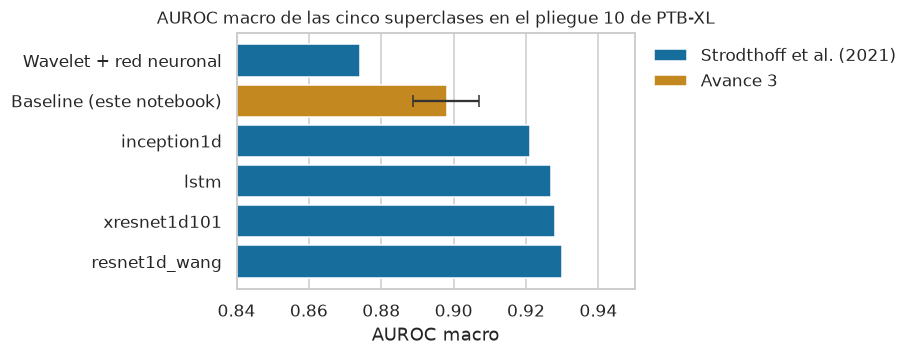

In [16]:
superclass_scores = {}
for name in SUPERCLASSES:
    model = baseline_model().fit(X.loc[train, FINAL_FEATURES], data.loc[train, name])
    superclass_scores[name] = model.predict_proba(X.loc[test, FINAL_FEATURES])[:, 1]
labels_test = data.loc[test, SUPERCLASSES].to_numpy()
per_class = {name: roc_auc_score(labels_test[:, i], superclass_scores[name]) for i, name in enumerate(SUPERCLASSES)}
macro = float(np.mean(list(per_class.values())))

score_matrix = np.column_stack([superclass_scores[name] for name in SUPERCLASSES])


def macro_auroc(labels: np.ndarray, scores: np.ndarray) -> float:
    return float(np.mean([roc_auc_score(labels[:, i], scores[:, i]) for i in range(labels.shape[1])]))


macro_low, macro_high = patient_bootstrap(macro_auroc, labels_test, score_matrix, patient_ids=patients_test)
display(pd.Series({**per_class, "macro": macro}, name="AUROC en prueba").to_frame().T.round(3))
print(f"AUROC macro: {macro:.3f}, IC 95% [{macro_low:.3f}, {macro_high:.3f}]")

BENCHMARK = {"Wavelet + red neuronal": 0.874, "inception1d": 0.921, "lstm": 0.927, "xresnet1d101": 0.928, "resnet1d_wang": 0.930}
reference = pd.DataFrame({"modelo": list(BENCHMARK) + ["Baseline (este notebook)"], "AUROC macro": list(BENCHMARK.values()) + [macro],
                          "origen": ["Strodthoff et al. (2021)"] * len(BENCHMARK) + ["Avance 3"]})
fig, ax = plt.subplots(figsize=(8.5, 3.4))
sns.barplot(data=reference.sort_values("AUROC macro"), x="AUROC macro", y="modelo", hue="origen", dodge=False, ax=ax)
ax.errorbar(macro, list(reference.sort_values("AUROC macro").modelo).index("Baseline (este notebook)"), xerr=[[macro - macro_low], [macro_high - macro]], color="0.2", capsize=4)
ax.set(xlim=(0.84, 0.95), ylabel="", title="AUROC macro de las cinco superclases en el pliegue 10 de PTB-XL")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1), title="", frameon=False)
plt.tight_layout()
plt.show()

### ¿Se alcanza el desempeño mínimo?

In [17]:
final_rank, rule_rank = ranking.loc[FINAL_NAME], ranking.loc["Regla clínica"]
criteria = pd.DataFrame([
    {"criterio": "AUROC mayor que el de la regla clínica (IC de la diferencia sin cero)",
     "resultado": f"diferencia {versus_rule['difference']:+.3f} [{versus_rule['ci_low']:+.3f}, {versus_rule['ci_high']:+.3f}]", "cumple": versus_rule["ci_low"] > 0},
    {"criterio": "Con 95% de sensibilidad, más normales sin derivar que la regla (IC sin traslape)",
     "resultado": f"especificidad {final_rank.esp_con_sens_95} contra {rule_rank.esp_con_sens_95}", "cumple": final_rank.esp95_inf > rule_rank.esp95_sup},
    {"criterio": "AUROC macro de las cinco superclases de al menos 0.874",
     "resultado": f"{macro:.3f} [{macro_low:.3f}, {macro_high:.3f}]", "cumple": macro >= 0.874},
]).set_index("criterio")
with pd.option_context("display.max_colwidth", None):
    display(criteria)

,resultado,cumple
criterio,,
AUROC mayor que el de la regla clínica (IC de la diferencia sin cero),"diferencia +0.157 [+0.139, +0.175]",True
"Con 95% de sensibilidad, más normales sin derivar que la regla (IC sin traslape)","especificidad 0.536 [0.438, 0.591] contra 0.000 [0.000, 0.000]",True
AUROC macro de las cinco superclases de al menos 0.874,"0.898 [0.889, 0.907]",True


El baseline cumple los tres criterios:

- Su AUROC en prueba es 0.917 [0.905, 0.929], contra 0.760 de la regla clínica. La diferencia es de +0.157, con un intervalo de [+0.139, +0.175].
- Con 95% de sensibilidad deja sin derivar al 53.6% [43.8%, 59.1%] de los normales. La regla no puede alcanzar esa sensibilidad sin derivar a todos (especificidad 0).
- Su AUROC macro en las cinco superclases es 0.898 [0.889, 0.907], por encima del 0.874 del método clásico del benchmark, aunque por debajo del rango de 0.921 a 0.930 de las redes convolucionales. Por superclase: `NORM` 0.924, `STTC` 0.917, `MI` 0.888, `CD` 0.886 y `HYP` 0.876.

Hay dos observaciones sobre la prueba.

La primera es que el AUROC del baseline baja de 0.935 en validación cruzada a 0.928 en el pliegue 9 y a 0.917 en el 10. La regla clínica, que no se ajusta a los datos, también baja (de 0.785 en entrenamiento a 0.760 en prueba), igual que gradient boosting (de 0.955 a 0.937). Como la regla no tiene parámetros que pudieran sobreajustarse, la caída indica que el pliegue 10 es más difícil para todos los métodos, no que el baseline se haya sobreajustado.

La segunda es que los umbrales fijados en entrenamiento no se trasladan igual de bien. El de derivación del 10% deja en prueba una especificidad de 0.907 [0.887, 0.925], muy cerca del 90% buscado, con una sensibilidad de 0.772. El de 95% de sensibilidad solo alcanza 0.915 [0.899, 0.930]. En esta prueba, el umbral fijado con los ECG normales se trasladó mejor que el fijado con las cardiopatías. Es un argumento a favor de fijar el punto de operación con ECG normales, que además son los más fáciles de reunir en una población universitaria.

Gradient boosting supera al baseline en prueba por +0.020 de AUROC [+0.013, +0.027]. Es el margen que un modelo más complejo ya demuestra sobre estas mismas características.

### Qué significa en un tamizaje real

La sensibilidad y la especificidad medidas en prueba no dependen de la prevalencia, pero el número de estudiantes derivados y el valor predictivo positivo (la fracción de derivados que de verdad tiene una alteración) sí. Con el umbral de derivación del 10% calculamos qué pasaría en 1,000 estudiantes con distintas prevalencias. Son escenarios hipotéticos: suponen que la sensibilidad y la especificidad de PTB-XL se trasladan a la población universitaria, lo que está por comprobarse.

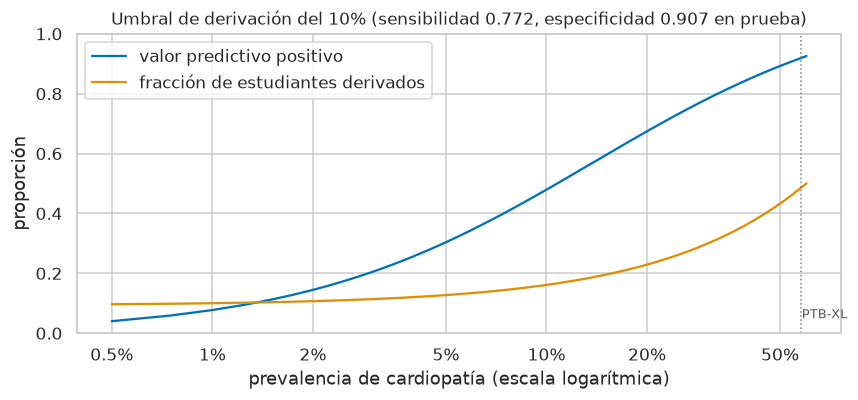

,con_alteración,detectados,no_detectados,sanos_derivados,total_derivados,valor_predictivo_positivo
prevalencia_%,,,,,,
1.0,10.0,7.72,2.28,92.27,99.99,0.08
2.0,20.0,15.44,4.56,91.34,106.78,0.14
5.0,50.0,38.60,11.40,88.54,127.15,0.30
10.0,100.0,77.21,22.79,83.88,161.09,0.48


In [18]:
point = points.loc[(FINAL_NAME, "derivación del 10% de normales")]
sensitivity, specificity = point["sens_valor"], point["esp_valor"]
prevalence = np.linspace(0.005, 0.6, 240)
ppv = sensitivity * prevalence / (sensitivity * prevalence + (1 - specificity) * (1 - prevalence))
referred = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
curves = pd.concat([pd.DataFrame({"prevalencia": prevalence, "valor": ppv, "medida": "valor predictivo positivo"}),
                    pd.DataFrame({"prevalencia": prevalence, "valor": referred, "medida": "fracción de estudiantes derivados"})])
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.lineplot(data=curves, x="prevalencia", y="valor", hue="medida", ax=ax)
ax.axvline(y[train].mean(), color="0.5", linestyle=":", linewidth=1)
ax.text(y[train].mean() + 0.005, 0.05, "PTB-XL", fontsize=8.5, color="0.35")
ticks = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
ax.set_xscale("log")
ax.set_xticks(ticks, [f"{100 * t:g}%" for t in ticks])
ax.minorticks_off()
ax.set(xlabel="prevalencia de cardiopatía (escala logarítmica)", ylabel="proporción", ylim=(0, 1),
       title=f"Umbral de derivación del 10% (sensibilidad {sensitivity:.3f}, especificidad {specificity:.3f} en prueba)")
ax.legend(title="")
plt.tight_layout()
plt.show()

per_thousand = pd.DataFrame([{"prevalencia_%": 100 * p, "con_alteración": 1000 * p, "detectados": 1000 * p * sensitivity, "no_detectados": 1000 * p * (1 - sensitivity),
                              "sanos_derivados": 1000 * (1 - p) * (1 - specificity), "total_derivados": 1000 * (p * sensitivity + (1 - p) * (1 - specificity)),
                              "valor_predictivo_positivo": p * sensitivity / (p * sensitivity + (1 - p) * (1 - specificity))} for p in (0.01, 0.02, 0.05, 0.10)])
display(per_thousand.set_index("prevalencia_%").round(2))

Con el umbral de derivación del 10%, la carga para el cardiólogo queda acotada: entre 100 y 161 estudiantes de cada 1,000 según la prevalencia. El valor predictivo positivo, en cambio, depende mucho de ella. Con una prevalencia de 5%, de 127 derivados 38.6 tienen una alteración (valor predictivo de 0.30) y 11.4 de los 50 casos no se detectan. Con 1%, 92 de cada 100 derivados están sanos (valor predictivo de 0.08).

Para el negocio esto significa que el baseline puede reducir a cerca de una décima parte los ECG que lee el cardiólogo, pero con este umbral deja pasar alrededor de uno de cada cuatro casos (sensibilidad de 0.772). El objetivo de los modelos siguientes es subir esa sensibilidad sin aumentar la carga de revisión.

## 9. Archivos del avance

Guardamos el modelo final, la lista de características, los umbrales y las métricas, para que los modelos de los siguientes avances se comparen contra exactamente este baseline. La carpeta `outputs/` no se versiona en Git.

In [19]:
joblib.dump({"model": final_model, "features": FINAL_FEATURES, "C": C_BEST, "thresholds": THRESHOLDS[FINAL_NAME]}, OUT / "baseline_logistica.joblib")
summary = {
    "dataset": "PTB-XL 1.0.3", "entrada": to_stored(TABLE) if TABLE.is_relative_to(ROOT) else TABLE.name, "python": platform.python_version(), "versiones": VERSIONS,
    "particion": {"train": "pliegues 1-8", "val": "pliegue 9", "test": "pliegue 10"},
    "modelo": "LogisticRegression (L2)", "C": C_BEST, "caracteristicas": FINAL_FEATURES, "umbrales": THRESHOLDS[FINAL_NAME],
    "validacion_cruzada": summarize(y[train], oof_final), "validacion": summarize(y[val], val_score[FINAL_NAME]),
    "prueba": {"binario": summarize(y_test, test_scores[FINAL_NAME]), "auroc_superclases": per_class, "auroc_macro": macro,
               "auroc_macro_ic95": [float(macro_low), float(macro_high)], "diferencia_auroc_vs_regla": versus_rule},
}
(OUT / "baseline_metricas.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float))
display(pd.DataFrame([{"archivo": f.name, "KB": round(f.stat().st_size / 1e3, 1)} for f in sorted(OUT.iterdir())]).set_index("archivo"))

,KB
archivo,
baseline_logistica.joblib,5.0
baseline_metricas.json,3.7


## 10. Conclusiones

El baseline muestra que el problema es viable y deja una referencia medida para los siguientes avances. Estas son las respuestas a las cinco preguntas del avance:

| Pregunta | Respuesta | Evidencia |
| --- | --- | --- |
| ¿Qué algoritmo usar como baseline? | Regresión logística con regularización L2 (`C = 0.1`) sobre las 111 características del Avance 2. | Datos tabulares y estandarizados, unos 150 ECG por parámetro, coeficientes interpretables y probabilidades para fijar el umbral. Supera a la regla clínica (0.935 contra 0.785 en validación cruzada) y al árbol interpretable (0.880). |
| ¿Qué características importan? | La repolarización y el QRS. El espectro, la calidad y la onda P casi no aportan. | Permutar la familia de repolarización baja el AUROC 0.199 y la del QRS 0.129; el resto suma menos de 0.04. RFE logra 0.934 con 50 de 111, pero en validación pierde 0.0025 [-0.0049, -0.0002], así que se conservan las 111. |
| ¿Sub o sobreajuste? | No hay sobreajuste. Hay un subajuste leve. | Brecha entre entrenamiento y validación cruzada de 0.003 en AUROC y de 0.008 en log loss. Las curvas de aprendizaje se juntan en 0.935, mientras gradient boosting llega a 0.955 con los mismos datos. |
| ¿Qué métrica usar? | AUROC para comparar modelos. Para operar, sensibilidad con un presupuesto fijo de normales derivados y especificidad con 95% de sensibilidad. | La exactitud premia al clasificador inútil cuando la prevalencia baja (98% de exactitud con sensibilidad 0 si la prevalencia es 2%). El AUROC no depende de la prevalencia, que en estudiantes será muy distinta del 58% de PTB-XL. |
| ¿Qué desempeño mínimo? | No existe un sistema histórico. El mínimo se fijó con la regla clínica y con el método clásico del benchmark de PTB-XL, y el baseline lo cumple. | AUROC de prueba 0.917, +0.157 sobre la regla. Con 95% de sensibilidad libera de revisión al 53.6% de los normales, contra 0% de la regla. AUROC macro de 0.898, contra 0.874 del método clásico. |

### Qué esperar de los modelos siguientes

- Hay margen, y ya se ve con las mismas características. Gradient boosting supera al baseline en prueba por 0.020 de AUROC [0.013, 0.027] y con 95% de sensibilidad deja sin derivar al 62.2% de los normales, contra 53.6% del baseline. Las redes convolucionales del benchmark llegan a 0.921-0.930 de AUROC macro, contra 0.898.
- Un modelo nuevo debe superar al baseline en el mismo pliegue de prueba y con el mismo bootstrap de pacientes. El modelo, las características, los umbrales y las métricas quedan guardados en `outputs/avance3_baseline/`.
- Más datos etiquetados no mejorarían el baseline: su curva de aprendizaje está casi plana. Los modelos más flexibles sí siguen ganando con más datos.

### Limitaciones

- PTB-XL no es la población del proyecto. Tiene 58% de cardiopatía y una mediana de edad de 62 años. Los valores predictivos de la sección 8 son escenarios que suponen que la sensibilidad y la especificidad se trasladan, y eso hay que comprobarlo con los datos del patrocinador. El Avance 2 mostró además que el ST elevado es frecuente en hombres jóvenes sanos, lo que puede generar falsas alarmas en estudiantes.
- Los umbrales no se trasladan exactamente: el de 95% de sensibilidad alcanzó 91.5% en prueba. El punto de operación debe volver a fijarse con ECG normales de la población local.
- La etiqueta es una aproximación basada en la lectura del ECG, no un diagnóstico confirmado, y agrupa enfermedades con efectos distintos.